In [ ]:
from huggingface_hub import login
login()

In [7]:
from pathlib import Path
import sys

import pandas as pd
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score
from sentence_transformers import SentenceTransformer

sys.path.insert(0, str(Path.cwd()))

from data import load_data, make_groups
from evaluation import evaluate, split_data

data = load_data("../data/processed/headlines.csv")
data["group"] = make_groups(data)
labels = sorted(data["label"].unique())
train_indices, test_indices = split_data(data)
train = data.iloc[train_indices]
test = data.iloc[test_indices]

train_sentences = train["headline"].tolist()
test_sentences = test["headline"].tolist()
print(f"Training rows: {len(train)}; test rows: {len(test)}")

Training rows: 323; test rows: 132


In [8]:
model = SentenceTransformer("djovak/embedic-large")

X_train = model.encode(
    train_sentences,
    batch_size=32,
    show_progress_bar=True,
    normalize_embeddings=True,
)

X_test = model.encode(
    test_sentences,
    batch_size=32,
    show_progress_bar=True,
    normalize_embeddings=True,
)

print(f"Embedding shapes: train={X_train.shape}; test={X_test.shape}")

Batches: 100%|██████████| 5/5 [00:01<00:00,  4.57it/s]

Embedding shapes: train=(323, 1024); test=(132, 1024)


In [9]:
classifier = LogisticRegression(
    max_iter=2000,
    class_weight="balanced",
    random_state=42,
)
classifier.fit(X_train, train["label"])
predictions = classifier.predict(X_test)
metrics = evaluate(test["label"], predictions, labels)
report = metrics["report"]

transformer_summary = {
    "accuracy": accuracy_score(test["label"], predictions),
    "macro_precision": report["macro avg"]["precision"],
    "macro_recall": report["macro avg"]["recall"],
    "macro_f1": report["macro avg"]["f1-score"],
    "weighted_f1": report["weighted avg"]["f1-score"],
    "test_rows": len(test),
}
print(transformer_summary)
display(
    pd.DataFrame(report).T[
        ["precision", "recall", "f1-score", "support"]
    ].round(3)
)

{'accuracy': 0.8257575757575758, 'macro_precision': 0.6277156177156178, 'macro_recall': 0.7277336747759283, 'macro_f1': 0.6663678109245047, 'weighted_f1': 0.7883122999689585, 'test_rows': 132}


,precision,recall,f1-score,support
nothing,0.909,0.909,0.909,22.000
personality_cult,0.583,1.000,0.737,7.000
vilifying_eu,0.000,0.000,0.000,12.000
vilifying_neighbours,0.800,0.800,0.800,20.000
vilifying_opponents,0.846,0.930,0.886,71.000
accuracy,0.826,0.826,0.826,0.826
macro avg,0.628,0.728,0.666,132.000
weighted avg,0.759,0.826,0.788,132.000


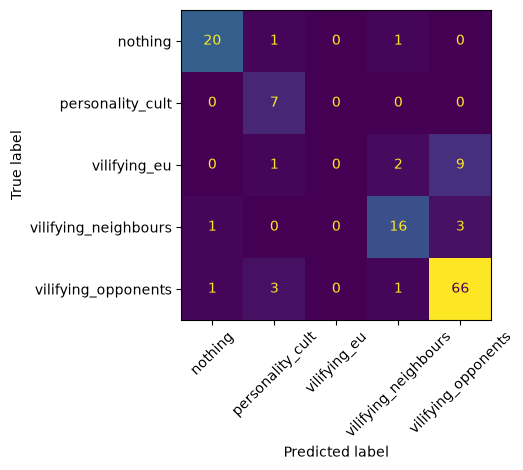

In [47]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

ConfusionMatrixDisplay(
    confusion_matrix=metrics["confusion_matrix"],
    display_labels=labels,
).plot(xticks_rotation=45, colorbar=False)
plt.tight_layout()
plt.show()

In [11]:
train_sentences

['NISMO NI SUMNJALI DA ĆE OVAKVA "GROMADA" STATI IZA BLOKADERA! Crnogorac koji podržava Srdanovića mrzi SPC, slavi lažnu državu Kosovo, divljao po Vatikanu (FOTO)',
 'TAČNO U 18.3O SATI: Predsednik Vučić obraća se naciji povodom presuda zločincima OVK',
 'PRESUDA VOĐAMA ZLOČINAČKE OVK, SVA ČETVORICA KRIVA ZA RATNE ZLOČINE: Hašimu Tačiju i Jakupu Krasnićiju po 25 godina zatvora! Veseljiju 18, Seljimiju 13! (VIDEO)',
 'DOKLE VIŠE DVOSTRUKI ARŠINI?! Briselu ne smeta sahrana krvnika Dinka Šakića u ustaškoj uniformi i veličanje ubica iz OVK, ali prete Srbiji zbog Mladića! (VIDEO)',
 '"UDALJITE SE ILI ĆEMO UPOTREBITI SILU" Haška policija u opremi za razbijanje demontracija ispred suda gde se čeka presuda vođama OVK, Tačiju i još trojici VIDEO',
 '"DETALJNIJE SAM GA UPOZNAO SA SVE IZRAŽENIJIM TENZIJAMA NA KOSOVU I METOHIJI" Predsednik Vučić razgovarao s komandantom Nacionalne garde Ohaja',
 'JEFTINA DEMAGOGIJA BLOKADERA! Analitičari: Umesto mladih snaga, "studentska" lista poturila istrošene 

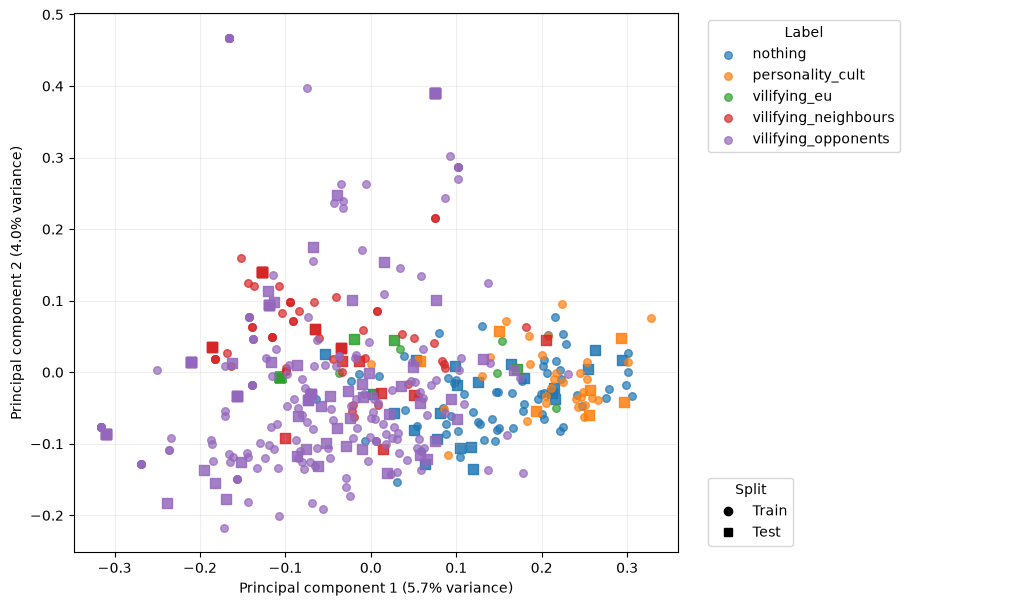

In [54]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from sklearn.decomposition import PCA

all_embeddings = np.concatenate([X_train, X_test])
pca = PCA(n_components=2)
all_projection = pca.fit_transform(all_embeddings)
train_projection = all_projection[:len(X_train)]
test_projection = all_projection[len(X_train):]

train_labels = train["label"].to_numpy()
test_labels = test["label"].to_numpy()
colors = plt.get_cmap("tab10")
figure = plt.figure(figsize=(12, 7))
grid = figure.add_gridspec(1, 2, width_ratios=[4, 2], wspace=0.05)
axis = figure.add_subplot(grid[0, 0])
legend_axis = figure.add_subplot(grid[0, 1])
legend_axis.set_axis_off()

for index, label in enumerate(labels):
    color = colors(index % 10)
    train_mask = train_labels == label
    test_mask = test_labels == label
    axis.scatter(
        train_projection[train_mask, 0],
        train_projection[train_mask, 1],
        color=color,
        alpha=0.7,
        s=30,
        marker="o",
        label=label,
    )
    axis.scatter(
        test_projection[test_mask, 0],
        test_projection[test_mask, 1],
        color=color,
        alpha=0.85,
        s=42,
        marker="s",
        label="_nolegend_",
    )

variance = pca.explained_variance_ratio_ * 100
axis.set_xlabel(f"Principal component 1 ({variance[0]:.1f}% variance)")
axis.set_ylabel(f"Principal component 2 ({variance[1]:.1f}% variance)")
axis.grid(alpha=0.2)
class_handles, class_labels = axis.get_legend_handles_labels()
class_legend = legend_axis.legend(
    class_handles,
    class_labels,
    title="Label",
    loc="upper left",
    # frameon=False,
)
legend_axis.add_artist(class_legend)
legend_axis.legend(
    handles=[
        Line2D([], [], color="black", marker="o", linestyle="None", label="Train"),
        Line2D([], [], color="black", marker="s", linestyle="None", label="Test"),
    ],
    title="Split",
    loc="lower left",
    # frameon=False,
)
plt.show()

In [18]:
import json

embedding_matrix = np.empty((len(data), X_train.shape[1]), dtype=np.float32)
embedding_matrix[train_indices] = X_train
embedding_matrix[test_indices] = X_test

export_data = data.copy()
export_data["embedding_model"] = "djovak/embedic-large"
export_data["embedding"] = [
    json.dumps(vector.tolist(), separators=(",", ":"))
    for vector in embedding_matrix
]

output_path = Path("../data/processed/headlines_with_embedic_large.csv")
output_path.parent.mkdir(parents=True, exist_ok=True)
export_data.to_csv(output_path, index=False)

exported = pd.read_csv(output_path)
vector_lengths = exported["embedding"].map(lambda value: len(json.loads(value)))
assert len(exported) == len(data)
assert vector_lengths.eq(X_train.shape[1]).all()
print(f"Wrote and verified {len(exported)} labelled headlines to {output_path}")
print(f"Embedding dimensions: {X_train.shape[1]}")
print(f"Columns: {list(exported.columns)}")

Wrote and verified 455 labelled headlines to ../data/processed/headlines_with_embedic_large.csv
Embedding dimensions: 1024
Columns: ['outlet', 'date', 'headline', 'url', 'summary', 'predicted_label', 'predicted_confidence', 'predicted_probs', 'model_version', 'label', 'comment', 'labelled_by', 'labelled_at', 'cluster_id', 'group', 'embedding_model', 'embedding']


In [40]:
label_counts = data["label"].value_counts().reindex(labels, fill_value=0)
label_counts = label_counts.rename("count").to_frame()
label_counts["%"] = (label_counts["count"] / label_counts["count"].sum() * 100).round(1)
print(label_counts.to_markdown())

| label                |   count |    % |
|:---------------------|--------:|-----:|
| nothing              |      84 | 18.5 |
| personality_cult     |      38 |  8.4 |
| vilifying_eu         |      19 |  4.2 |
| vilifying_neighbours |      69 | 15.2 |
| vilifying_opponents  |     245 | 53.8 |
